# 2010 JO179: A Dwarf Planet in the 21:5 Resonance with Neptune

*Matthew Payne*

2010 JO179 is a trans-Neptunian object (TNO) found by the Pan-STARRS Outer Solar System Survey, 600–900 km across and therefore a dwarf-planet candidate. Its orbit, 78 au from the Sun on average, is so well determined that its long-term dynamics can be followed in detail: it sits in the 21:5 mean-motion resonance with Neptune, completing 5 orbits for every 21 of Neptune's.

This notebook repeats the dynamical analysis of

> M. J. Holman, M. J. Payne, W. Fraser, P. Lacerda, M. T. Bannister et al. (2018), *A Dwarf Planet Class Object in the 21:5 Resonance with Neptune*, ApJL **855**, L6. [ADS](https://ui.adsabs.harvard.edu/abs/2018ApJ...855L...6H/abstract) · [arXiv:1709.05427](https://arxiv.org/abs/1709.05427)

(H18), starting from the orbit the Minor Planet Center publishes today. We will:

1. Fetch the orbit from the MPC Orbits API and parse it with the `mpc_orb` package, and check it against H18's.
2. Integrate it with the Sun and the giant planets, and watch the resonant angle librate.
3. Make 100 clones of the orbit from its covariance matrix and follow them for 700 million years, as H18 did, to see how long the resonance holds.

**Requirements:** `numpy`, `matplotlib`, `rebound`, `mpc_orb` and `requests` (for fetching the orbit and planet positions; copies are kept in `data/`).

**Run time:** the 700-million-year integration takes one to two hours on 12 cores and is cached in `cache/`, so the notebook normally runs in under a minute. Set `RECOMPUTE = True` to redo it, or `QUICK = True` for 12 clones over 50 million years (a few minutes).

In [1]:
import os
import time
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np
from mpc_orb.parse import MPCORB

import jo179    # helper module in this folder

QUICK = False
RECOMPUTE = False
CACHE = "cache_quick" if QUICK else "cache"
NPROC = os.cpu_count()
os.makedirs(CACHE, exist_ok=True)
DEG = np.pi / 180

## 1. The orbit

The MPC Orbits API returns an object's orbit in the `mpc_orb` JSON format: the best-fit state in several element sets, each with its covariance matrix, plus details of the fit. `jo179.fetch_orbit` keeps a copy in `data/`; delete it to fetch the current orbit.

In [2]:
mo = jo179.fetch_orbit("2010 JO179", "data/2010JO179_mpc_orb.json")
M = MPCORB(mo)
fit = M.orbit_fit_statistics
epoch_jd = 2400000.5 + M.epoch_data["epoch"]
print(f"Epoch MJD {M.epoch_data['epoch']} ({M.epoch_data['timesystem']}); arc {fit['arc_length_sel']}, "
      f"{fit['nobs_total_sel']} observations over {fit['nopp']} oppositions")
for name, el in M.COM.element_dict.items():
    print(f"   {name:10s} {el['val']:16.8f} ± {el['unc']:.2g}")

Epoch MJD 61200.0 (TDT); arc 1951-2026, 222 observations over 16 oppositions
   q               39.13533684 ± 0.00029
   e                0.49888107 ± 1.1e-05
   i               32.06386497 ± 5.7e-06
   node           147.04624420 ± 5.9e-05
   argperi          9.49743129 ± 0.0013
   peri_time    33891.53767630 ± 0.26


H18 fitted an arc of 2005–2016. The MPC's orbit now spans 1951–2026, thanks to precovery observations in old photographic plates, so it is far better determined. As a check, we integrate it back to H18's epoch (JD 2455327.1) and compare barycentric elements with their Table 2.

The planets come from JPL Horizons at the orbit's epoch (`jo179.planet_states`, also cached in `data/`). As in H18, the simulation contains the Sun and the four giant planets; we add the masses of the terrestrial planets to the Sun's.

In [3]:
planets = jo179.planet_states(epoch_jd, f"data/planets_JD{epoch_jd}.json")
best = jo179.clone_states(M.CAR.coefficient_values, M.CAR.covariance_array, 0, 1)
sim = jo179.make_sim(planets, best, integrator="ias15")
sim.integrate((2455327.1 - epoch_jd) / jo179.DAYS_PER_YEAR)
oN, (o,) = jo179.bary_elements(sim)
t_peri = 2455327.1 - o.M / o.n * jo179.DAYS_PER_YEAR
h18 = [("a (au)", 78.307, 0.009, o.a), ("e", 0.49781, 0.00005, o.e), ("i (deg)", 32.04342, 0.00001, o.inc / DEG),
       ("node (deg)", 147.1722, 0.0002, o.Omega / DEG), ("arg. peri. (deg)", 9.824, 0.005, o.omega / DEG), ("T_peri (JD)", 2433937.1, 0.8, t_peri)]
print("                     H18 Table 2              MPC orbit today     difference / H18's sigma")
for name, v, s, mine in h18:
    print(f"   {name:16s} {v:14.5f} ± {s:<8g} {mine:16.5f}     {(mine - v) / s:+6.1f}")

                     H18 Table 2              MPC orbit today     difference / H18's sigma
   a (au)                 78.30700 ± 0.009            78.31139       +0.5
   e                       0.49781 ± 5e-05             0.49789       +1.7
   i (deg)                32.04342 ± 1e-05            32.04350       +7.7
   node (deg)            147.17220 ± 0.0002          147.17145       -3.7
   arg. peri. (deg)        9.82400 ± 0.005             9.82029       -0.7
   T_peri (JD)       2433937.10000 ± 0.8         2433939.07998       +2.5


The two orbits agree. The semi-major axis, eccentricity, argument of pericentre and time of pericentre differ by less than three of H18's standard deviations. The inclination and node differ by 0.3″ and 2.5″, several times H18's very small quoted uncertainties; small differences in the reference frame or in the treatment of the planets, or slightly optimistic uncertainties from the shorter arc, could account for this. None of it matters for the dynamics below.

## 2. The resonance

A TNO in the 21:5 resonance has an orbital period 21/5 = 4.2 times Neptune's. The resonance is protected by the *resonant angle*

$$\theta = 21\lambda - 5\lambda_N - 16\varpi$$

(H18 Eq. 1), built from the TNO's mean longitude $\lambda$ and longitude of pericentre $\varpi$ and Neptune's mean longitude $\lambda_N$. It measures where Neptune is when the TNO reaches pericentre. Outside the resonance $\theta$ circulates through all values; in it, $\theta$ *librates* about a fixed value, here about 180°, which keeps the TNO's pericentre passages away from Neptune.

We follow the best-fit orbit for 3 million years with REBOUND's WHFast integrator (a 0.5-year step with symplectic correctors). H18 used IAS15; over the first million years the two give resonant angles that agree to 0.003°, and WHFast is about 40 times faster.

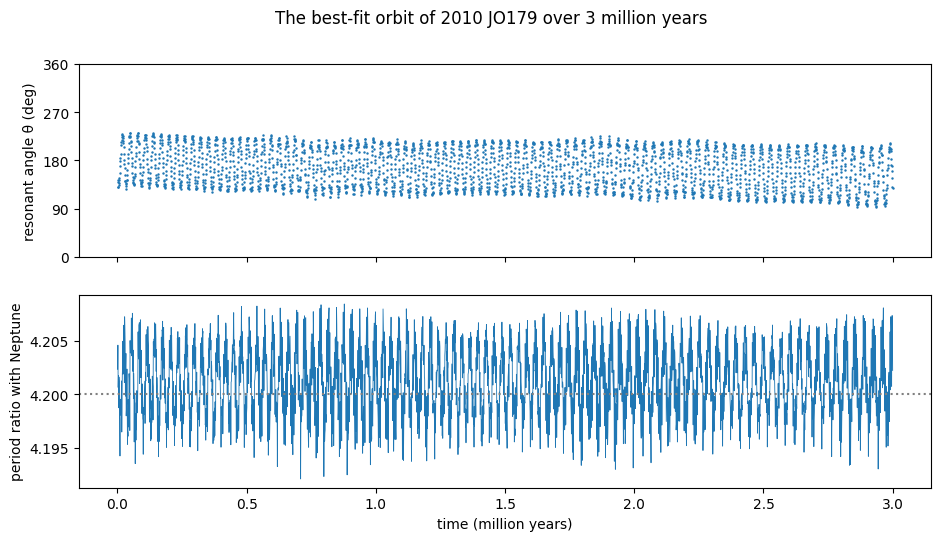

θ stays between 94° and 232°; libration period about 35 thousand years
Period ratio between 4.1921 and 4.2084
The 16 possible 21:5 angles (n = 0 is H18 Eq. 1): turns covered in 3 Myr: 0.4 2.0 3.7 5.4 7.1 8.8 10.5 13.2 14.9 17.6 21.3 27.0 34.7 36.4 39.1 50.8


In [4]:
sim = jo179.make_sim(planets, best)
T = np.arange(1000.0, 3.0e6 + 1, 1000.0)
th, pr, th_all = [], [], []
for t in T:
    sim.integrate(t, exact_finish_time=0)
    oN, (o,) = jo179.bary_elements(sim)
    th.append(jo179.theta(o, oN)); pr.append(o.P / oN.P)
    th_all.append([jo179.theta(o, oN, n) for n in range(16)])
th, pr, th_all = np.degrees(th), np.array(pr), np.degrees(th_all)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
a1.plot(T / 1e6, th, ".", ms=1.5)
a1.set(ylabel="resonant angle θ (deg)", ylim=(0, 360), yticks=[0, 90, 180, 270, 360])
a2.plot(T / 1e6, pr, lw=0.6)
a2.axhline(4.2, color="0.5", ls=":")
a2.set(xlabel="time (million years)", ylabel="period ratio with Neptune")
fig.suptitle("The best-fit orbit of 2010 JO179 over 3 million years", y=0.98)
plt.show()

spec = np.abs(np.fft.rfft(np.cos(np.radians(th)) - np.cos(np.radians(th)).mean()))
freq = np.fft.rfftfreq(len(th), 1000.0)
print(f"θ stays between {th.min():.0f}° and {th.max():.0f}°; libration period about {1 / freq[1:][np.argmax(spec[1:])] / 1e3:.0f} thousand years")
print(f"Period ratio between {pr.min():.4f} and {pr.max():.4f}")
span = [np.ptp(np.unwrap(np.radians(th_all[:, n]))) / (2 * np.pi) for n in range(16)]
print("The 16 possible 21:5 angles (n = 0 is H18 Eq. 1): turns covered in 3 Myr:", " ".join(f"{s:.1f}" for s in span))

The resonant angle librates between about 94° and 232°, centred near 165°, with a period of about 35,000 years, while the period ratio oscillates about 4.2. H18 checked all 16 angles that the 21:5 resonance allows (with $-16\varpi$ replaced by $-(n\varpi_N + (16-n)\varpi)$) and found that only theirs, $n = 0$, ever librates. We find the same: over 3 million years the $n = 0$ angle never completes a turn, while every other one circulates, from twice to fifty times.

## 3. The resonance as seen from Neptune

In a frame that rotates with Neptune, a resonant orbit traces a pattern that repeats every 21 Neptune orbits (5 orbits of the TNO, about 3,460 years). Each pass of the TNO through pericentre happens 21/5 of a Neptune orbit after the previous one, so in this frame the five pericentres of a cycle fall $360° \times 21/5 = 1512°$, that is 72°, apart. The resonance keeps Neptune, fixed in this frame, away from all five.

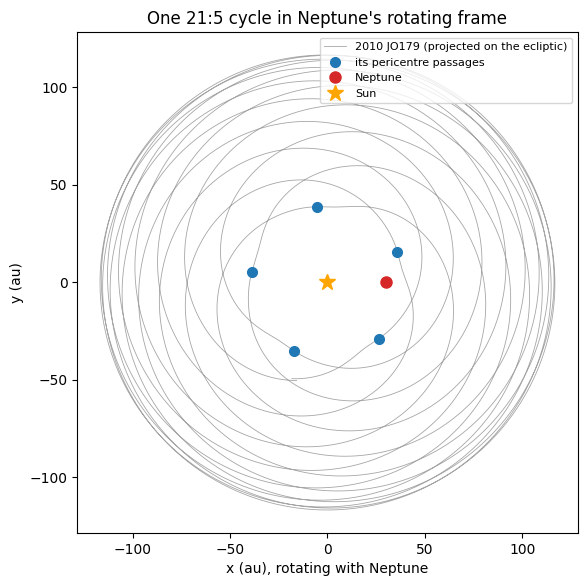

5 pericentre passages, at longitudes (Neptune at 0°): 24°, 98°, 172°, 244°, 312°
Closest pericentre to Neptune's direction: 24°


In [5]:
sim = jo179.make_sim(planets, best)
P_N = sim.particles["Neptune"].P
xy, rr, nep = [], [], None
for t in np.linspace(0, 21 * P_N, 8000):
    sim.integrate(t, exact_finish_time=1)
    bary = sim.com(last=5)
    pn, pt = sim.particles["Neptune"], sim.particles[5]
    ang = np.arctan2(pn.y - bary.y, pn.x - bary.x)
    c, s = np.cos(-ang), np.sin(-ang)
    dx, dy = pt.x - bary.x, pt.y - bary.y
    xy.append((c * dx - s * dy, s * dx + c * dy))
    rr.append(np.sqrt(dx * dx + dy * dy + (pt.z - bary.z) ** 2))
    nep = np.hypot(pn.x - bary.x, pn.y - bary.y)
xy, rr = np.array(xy), np.array(rr)
peri = [k for k in range(1, len(rr) - 1) if rr[k] < rr[k - 1] and rr[k] < rr[k + 1]]
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.plot(xy[:, 0], xy[:, 1], lw=0.6, color="0.65", label="2010 JO179 (projected on the ecliptic)")
ax.plot(xy[peri, 0], xy[peri, 1], "o", color="C0", ms=7, label="its pericentre passages")
ax.plot([nep], [0], "o", color="C3", ms=8, label="Neptune")
ax.plot([0], [0], "*", color="orange", ms=12, label="Sun")
ax.set(aspect="equal", xlabel="x (au), rotating with Neptune", ylabel="y (au)")
ax.legend(fontsize=8, loc="upper right")
ax.set_title("One 21:5 cycle in Neptune's rotating frame")
plt.show()
lon = np.sort(np.degrees(np.arctan2(xy[peri, 1], xy[peri, 0])) % 360)
print(f"{len(peri)} pericentre passages, at longitudes (Neptune at 0°): " + ", ".join(f"{v:.0f}°" for v in lon))
print(f"Closest pericentre to Neptune's direction: {min(min(v, 360 - v) for v in lon):.0f}°")

The five pericentres sit about 72° apart, at 39 au from the Sun, and Neptune, at 30 au, lies between two of them, 24° from the nearer. As the resonant angle librates, the whole pattern rocks back and forth, but Neptune never comes close to one of the pericentres: this is the protection the resonance provides.

## 4. Clones and the long-term behaviour

An orbit determined from observations is only known within its uncertainties, and the outer Solar System is chaotic on long timescales, so a single integration says little about the next few hundred million years. H18 made 100 clones by perturbing the observations within their errors and refitting; we draw 100 clones from the covariance matrix of the MPC's orbit (`jo179.clone_states`), which is equivalent while the uncertainties are small. Because today's orbit is so much better determined, our clones start far closer together than H18's.

Each clone is integrated for 700 million years. In each 2-million-year window, a clone counts as *resonant* if its resonant angle never comes within 10° of 0°, the point opposite the libration centre; circulation sweeps through every angle within a window.

In [6]:
N_CLONES = 11 if QUICK else 100
T_END = 5.0e7 if QUICK else 7.0e8
WINDOW, CADENCE, GAP = 2.0e6, 1000.0, 10.0
KEEP, KEEP_EVERY = list(range(8)), 2.0e4          # full histories for the best fit and 7 clones
X = jo179.clone_states(M.CAR.coefficient_values, M.CAR.covariance_array, N_CLONES, seed=2018)
_, oc = jo179.bary_elements(jo179.make_sim(planets, X[1:]))
print(f"{N_CLONES} clones; spread in barycentric semi-major axis at the epoch: {np.std([o.a for o in oc]) * 1e3:.2f} × 10⁻³ au "
      f"(H18's 1σ, from the 2005-2016 arc: 9 × 10⁻³ au)")

path = os.path.join(CACHE, f"clones_{N_CLONES}_{int(T_END / 1e6)}Myr.npz")
if os.path.exists(path) and not RECOMPUTE:
    z = np.load(path)
    run = {k: z[k] for k in z.files}
else:
    t0 = time.time()
    ids = np.arange(N_CLONES + 1)
    batches = np.array_split(ids, min(NPROC, len(ids)))
    jobs = [(planets, X[b], list(b), T_END, CADENCE, WINDOW, GAP, KEEP, KEEP_EVERY) for b in batches]
    with Pool(len(jobs)) as pool:
        parts = pool.map(jo179.long_run, jobs, chunksize=1)
    run = {k: np.concatenate([p[k] for p in parts]) for k in ("flags", "pr_min", "pr_max", "q_min", "q_max", "e_mean", "i_mean")}
    for cid in KEEP:
        s = next(p["series"][cid] for p in parts if cid in p["series"])
        for k, v in s.items():
            run[f"s{cid}_{k}"] = v
    np.savez_compressed(path, **run)
    print(f"({time.time() - t0:.0f} s)")
t_win = (np.arange(run["flags"].shape[1]) + 0.5) * WINDOW

100 clones; spread in barycentric semi-major axis at the epoch: 2.62 × 10⁻³ au (H18's 1σ, from the 2005-2016 arc: 9 × 10⁻³ au)


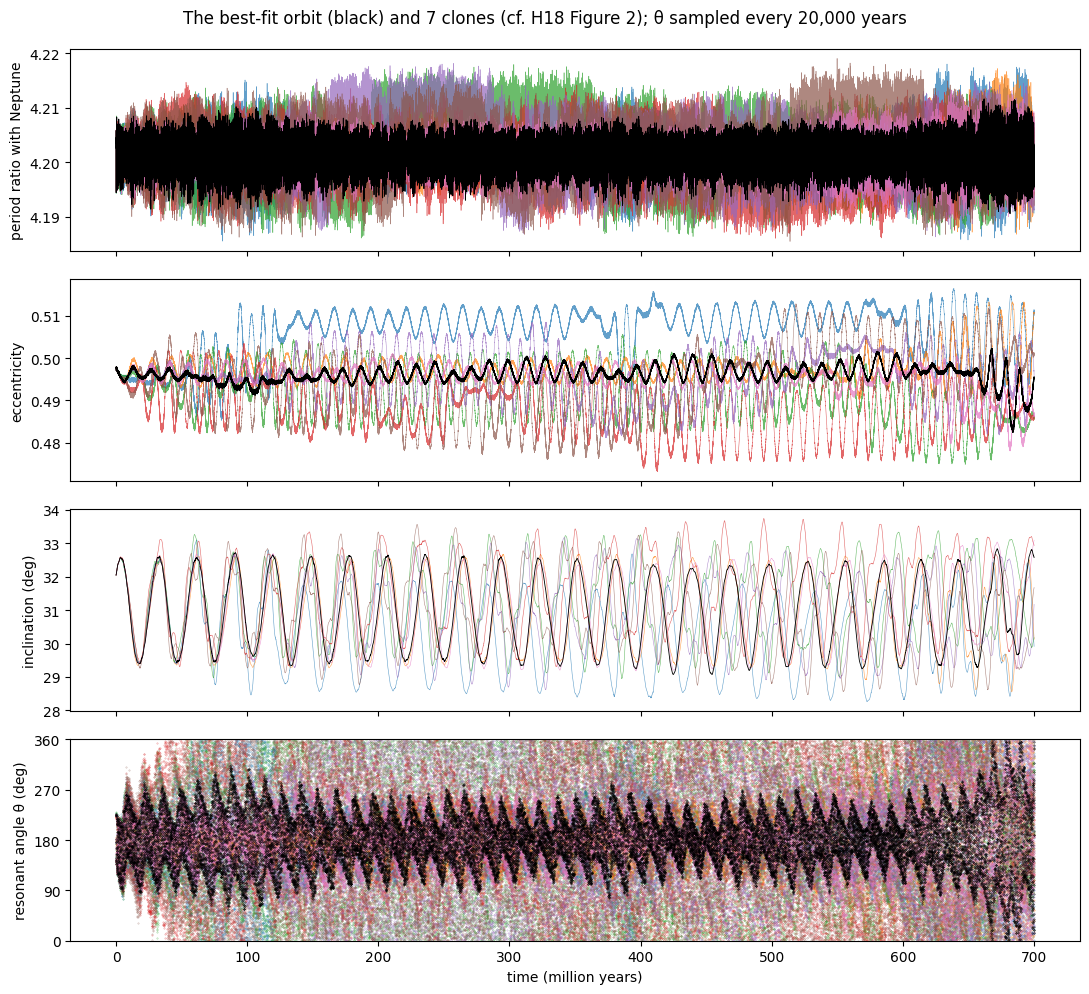

In [7]:
t_keep = (np.arange(len(run["s0_theta"])) + 1) * KEEP_EVERY
fig, axs = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
for cid in KEEP:
    kw = dict(color="k", lw=0.6, zorder=3) if cid == 0 else dict(lw=0.4, alpha=0.7)
    axs[0].plot(t_keep / 1e6, run[f"s{cid}_pr"], **kw)
    axs[1].plot(t_keep / 1e6, run[f"s{cid}_e"], **kw)
    axs[2].plot(t_keep / 1e6, run[f"s{cid}_i"] / DEG, **kw)
    axs[3].plot(t_keep / 1e6, run[f"s{cid}_theta"] / DEG, ".", ms=0.6, **({"color": "k", "zorder": 3} if cid == 0 else {"alpha": 0.5}))
axs[0].set_ylabel("period ratio with Neptune"); axs[1].set_ylabel("eccentricity"); axs[2].set_ylabel("inclination (deg)")
axs[3].set(ylabel="resonant angle θ (deg)", ylim=(0, 360), yticks=[0, 90, 180, 270, 360], xlabel="time (million years)")
fig.suptitle("The best-fit orbit (black) and 7 clones (cf. H18 Figure 2); θ sampled every 20,000 years", y=0.99)
fig.tight_layout()
plt.show()

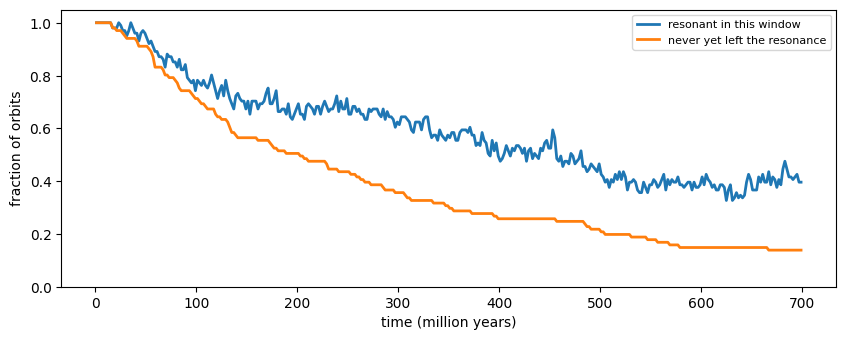

All 101 orbits (best fit and clones) resonant in the first window: True
Median time of first exit from the resonance: 203 Myr (H18: about 110 Myr)
Resonant in the last window (700 Myr): 40% (H18: about 25%)
Resonant throughout: 14% (H18: about 6%)
Best fit: first leaves the resonance at 667 Myr; resonant in 98% of windows
Period ratio range over all orbits: 4.179 - 4.224 (H18: 4.185 - 4.215)
Pericentre range: 36.4 - 41.7 au (H18: 37.5 - 41.5 au)


In [8]:
flags = run["flags"]
resonant_now = flags.mean(axis=0)
first_exit = np.array([t_win[np.argmin(f)] if not f.all() else np.inf for f in flags])
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(t_win / 1e6, resonant_now, color="C0", lw=2, label="resonant in this window")
ax.plot(t_win / 1e6, [np.mean(first_exit > t) for t in t_win], color="C1", lw=2, label="never yet left the resonance")
ax.set(xlabel="time (million years)", ylabel="fraction of orbits", ylim=(0, 1.05))
ax.legend(fontsize=8)
plt.show()

n = len(flags)
print(f"All {n} orbits (best fit and clones) resonant in the first window: {flags[:, 0].all()}")
med = np.median(first_exit)
print("Median time of first exit from the resonance: " + (f"{med / 1e6:.0f} Myr" if np.isfinite(med) else f"more than {T_END / 1e6:.0f} Myr (most never leave)") + " (H18: about 110 Myr)")
print(f"Resonant in the last window ({T_END / 1e6:.0f} Myr): {resonant_now[-1]:.0%} (H18: about 25%)")
print(f"Resonant throughout: {np.mean(flags.all(axis=1)):.0%} (H18: about 6%)")
print("Best fit: " + (f"first leaves the resonance at {first_exit[0] / 1e6:.0f} Myr" if np.isfinite(first_exit[0]) else "never leaves the resonance")
      + f"; resonant in {flags[0].mean():.0%} of windows")
print(f"Period ratio range over all orbits: {run['pr_min'].min():.3f} - {run['pr_max'].max():.3f} (H18: 4.185 - 4.215)")
print(f"Pericentre range: {run['q_min'].min():.1f} - {run['q_max'].max():.1f} au (H18: 37.5 - 41.5 au)")

The clones behave as H18's did. All start in the resonance, and all wander in and out of it on timescales of a hundred million years, while their period ratios stay close to 4.2 and their pericentres between about 36 and 42 au: 2010 JO179 is *metastable*, a resonant object that will not stay resonant forever. The inclination and eccentricity oscillate with a period of about 27 million years, and the libration amplitude grows and shrinks with them.

Numerically our clones are somewhat more stable than H18's. Their median first exit from the resonance comes at 203 million years rather than about 110; 40% are resonant at 700 million years rather than about 25%; and 14% stay resonant throughout, against about 6%. Several things may contribute. Today's orbit is better determined, so our clones start about 3.4 times closer together in semi-major axis. Our test for "resonant" is our own, since H18 do not state theirs. And with 100 chaotic clones, these fractions carry sampling uncertainties of about ±5 percentage points. Our ranges of period ratio (4.179–4.224) and pericentre (36.4–41.7 au) are slightly wider than H18's (4.185–4.215 and 37.5–41.5 au).

Individual trajectories differ more. Our best-fit orbit is resonant in 98% of the windows, first leaving at 667 million years; H18's best fit left after 70–100 million years (their caption and text give both figures) and later returned. In a chaotic system, single trajectories diverge, which is exactly why both studies use clones.

## Summary

* The MPC's orbit for 2010 JO179, now based on observations from 1951 to 2026, agrees with H18's 2005–2016 orbit, and is several times better determined.
* 2010 JO179 is in the 21:5 resonance with Neptune: the resonant angle $21\lambda - 5\lambda_N - 16\varpi$ librates about 165° with a period of about 35,000 years, and it is the only one of the resonance's 16 angles that does.
* Over 700 million years, clones of the orbit drift in and out of the resonance: the median clone first leaves it after about 200 million years, and 40% are resonant at the end. H18 found the same metastable behaviour, with somewhat faster leakage (110 million years and 25%).
* Large, distant resonant objects like this imply a substantial population that moves between the high-order resonances, the detached population and the scattering disk.

## Going further

* **Other resonances.** The same method applies to any TNO whose orbit the MPC publishes: change the designation in `jo179.fetch_orbit` and the integers in `jo179.P` and `jo179.Q`. The 9:2 resonant dwarf-planet candidate 2015 RR245 is a good next case.
* **Better clones.** Sampling the covariance assumes the uncertainties are small and Gaussian, which is excellent for an orbit with a 75-year arc. For short arcs, refitting perturbed observations, as H18 did, is more robust.
* **Neptune's migration.** How 2010 JO179 got into the resonance is a separate question: resonances like this were probably populated as Neptune migrated outward, and objects leak in and out over billions of years, as these clones do.

## References

* Bannister, M. T. et al. 2016, *OSSOS. IV. Discovery of a Dwarf Planet Candidate in the 9:2 Resonance with Neptune*, AJ 152, 212. [ADS](https://ui.adsabs.harvard.edu/abs/2016AJ....152..212B/abstract)
* Holman, M. J., Payne, M. J., Fraser, W. et al. 2018, *A Dwarf Planet Class Object in the 21:5 Resonance with Neptune*, ApJL 855, L6. [ADS](https://ui.adsabs.harvard.edu/abs/2018ApJ...855L...6H/abstract)
* Rein, H. & Liu, S.-F. 2012, *REBOUND: an open-source multi-purpose N-body code for collisional dynamics*, A&A 537, A128. [ADS](https://ui.adsabs.harvard.edu/abs/2012A%26A...537A.128R/abstract)
* Rein, H. & Tamayo, D. 2015, *WHFAST: a fast and unbiased implementation of a symplectic Wisdom-Holman integrator for long-term gravitational simulations*, MNRAS 452, 376. [ADS](https://ui.adsabs.harvard.edu/abs/2015MNRAS.452..376R/abstract)
* Rein, H. & Spiegel, D. S. 2015, *IAS15: a fast, adaptive, high-order integrator for gravitational dynamics, accurate to machine precision over a billion orbits*, MNRAS 446, 1424. [ADS](https://ui.adsabs.harvard.edu/abs/2015MNRAS.446.1424R/abstract)